# Assignment 3

**Name:** Albert Kabore

**Academic status:** PhD student in Advanced and Equitable Computing

## Introduction

This assignment connects the matrix representation of quantum gates with the states and measurement outcomes of two-qubit circuits. For each circuit in Question 1, the analysis derives a 4×4 operator using the Kronecker product, applies it to all four computational-basis inputs, and calculates the output probabilities. Qiskit checks the operators and basis actions, while histogram snapshots compare the predicted probabilities with sampled simulator counts. Question 2 examines the creation of an entangled Bell state, and Question 3 explains how IBM represents and controls physical qubits using superconducting circuits.

### Basis, notation, and simulation setup

Use the ordered basis |00⟩, |01⟩, |10⟩, |11⟩, with kets written |q1 q0⟩ as in Qiskit. A gate on q0 is the right tensor factor; a gate on q1 is the left tensor factor. Later gates multiply on the left. For two 2×2 matrices, the Kronecker product replaces each entry of the first matrix by that entry times the second matrix, producing four 2×2 blocks in a 4×4 operator.

For input |ψ_i⟩, the output is |ψ_f⟩ = U|ψ_i⟩. A basis input selects its corresponding matrix column. The Born rule gives $P(b)=|\langle b|\psi_f\rangle|^2$; the four probabilities sum to 1. The assignment writes the conjugate overlap $|\langle\psi_f|b\rangle|^2$, which has the same squared magnitude.

The Question 1 circuits start in Qiskit's default input |00⟩. Each histogram is generated by running the assigned circuit for 1024 shots on an ideal AerSimulator with seed 2026. The displayed counts are simulator measurements, not IBM hardware measurements. Expected counts are 1024 times the predicted probability; finite sampling can make observed counts differ from that expectation.

Run this notebook with the project's Python 3.11 (.venv) kernel. Define the gates and check each assigned operator and its four basis actions against Qiskit before sampling its measurements.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator, Statevector
from qiskit.visualization import plot_histogram, array_to_latex
from qiskit_aer import AerSimulator
from IPython.display import display, Markdown

SHOTS, SEED = 1024, 2026
BASIS = ["00", "01", "10", "11"]  # |q1 q0>
sim = AerSimulator(seed_simulator=SEED)
I2 = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)

def analyze(qc, U_hand, label):
    assert np.allclose(Operator(qc).data, U_hand)
    assert np.allclose(U_hand.conj().T @ U_hand, np.eye(4))
    for k, bits in enumerate(BASIS):
        actual = Statevector.from_label(bits).evolve(qc).data
        assert np.allclose(actual, U_hand[:, k])
    print(f"{label}: operator and all four basis actions verified against Qiskit.")
    display(Markdown(f"### Circuit Diagram: {label}"))
    with plt.rc_context():
        circuit_figure = qc.draw("mpl", initial_state=True, idle_wires=True, fold=-1)
        display(circuit_figure)
        plt.close(circuit_figure)
    display(Markdown("Wire order: q0 above q1; basis kets use |q1 q0⟩."))
    psi = Statevector.from_label("00").evolve(qc).data
    probabilities = {b: float(abs(psi[k]) ** 2) for k, b in enumerate(BASIS)}
    assert np.isclose(sum(probabilities.values()), 1)
    display(Markdown("**State vector at the circuit output:**"))
    display(array_to_latex(psi.reshape(-1, 1), prefix=r"|\psi_f\rangle = "))
    measured = qc.copy()
    measured.measure_all()
    sampled = sim.run(transpile(measured, sim), shots=SHOTS).result().get_counts()
    counts = {b: sampled.get(b, 0) for b in BASIS}
    assert sum(counts.values()) == SHOTS
    assert all(counts[b] == 0 for b in BASIS if np.isclose(probabilities[b], 0))
    rows = ["| Outcome | Exact probability | Expected count | Observed count |",
            "|---|---:|---:|---:|"]
    for b in BASIS:
        rows.append(
            f"| {b} | {probabilities[b]:.2f} | "
            f"{SHOTS * probabilities[b]:.0f} | {counts[b]} |"
        )
    display(Markdown("\n".join(rows)))
    return counts

print("Setup ready: NumPy, Matplotlib, Qiskit, and AerSimulator loaded.")

Setup ready: NumPy, Matplotlib, Qiskit, and AerSimulator loaded.


## Question 1(a)

### 4×4 Operator Using the Kronecker Product Formulation

The first gate is X on q0: I ⊗ X. The second is X on q1: X ⊗ I. Thus U = (X ⊗ I)(I ⊗ X) = (XI) ⊗ (IX) = X ⊗ X.

The entries of the left X are 0,1,1,0. They scale the four blocks in that order.

$$ X = \begin{bmatrix}0 & 1\\1 & 0\end{bmatrix}. $$

**Single-qubit actions:**

Multiply the two matrix rows by the input column. These are the only single-qubit actions needed for this part.

**Input $X|0\rangle$:**

$$ 0\cdot1 + 1\cdot0 = 0 $$

$$ 1\cdot1 + 0\cdot0 = 1 $$

Therefore $ X|0\rangle = |1\rangle $.

**Input $X|1\rangle$:**

$$ 0\cdot0 + 1\cdot1 = 1 $$

$$ 1\cdot0 + 0\cdot1 = 0 $$

Therefore $ X|1\rangle = |0\rangle $.

**Kronecker product expansion:**

Each entry of the left factor multiplies **every** entry of the right factor.

**Upper-left block:**

$$ (0)X = \begin{bmatrix}(0)\cdot(0) & (0)\cdot(1)\\(0)\cdot(1) & (0)\cdot(0)\end{bmatrix} $$

$$ = \begin{bmatrix}0 & 0\\0 & 0\end{bmatrix}. $$

**Upper-right block:**

$$ (1)X = \begin{bmatrix}(1)\cdot(0) & (1)\cdot(1)\\(1)\cdot(1) & (1)\cdot(0)\end{bmatrix} $$

$$ = \begin{bmatrix}0 & 1\\1 & 0\end{bmatrix}. $$

**Lower-left block:**

$$ (1)X = \begin{bmatrix}(1)\cdot(0) & (1)\cdot(1)\\(1)\cdot(1) & (1)\cdot(0)\end{bmatrix} $$

$$ = \begin{bmatrix}0 & 1\\1 & 0\end{bmatrix}. $$

**Lower-right block:**

$$ (0)X = \begin{bmatrix}(0)\cdot(0) & (0)\cdot(1)\\(0)\cdot(1) & (0)\cdot(0)\end{bmatrix} $$

$$ = \begin{bmatrix}0 & 0\\0 & 0\end{bmatrix}. $$

Place the upper two blocks side by side, then the lower two blocks:

$$ U = X \otimes X = \begin{bmatrix}0 & 0 & 0 & 1\\0 & 0 & 1 & 0\\0 & 1 & 0 & 0\\1 & 0 & 0 & 0\end{bmatrix}. $$

### Action of the Operator on the Kets: |00⟩, |01⟩, |10⟩, |11⟩

Use the single-qubit actions above. Multiply any scalar phases and distribute tensor products before combining the two bits.

**Input $|00\rangle$:**

$$ U|00\rangle = (X|0\rangle) \otimes (X|0\rangle) $$

$$  = |1\rangle \otimes |1\rangle $$

$$  = |11\rangle $$

**Input $|01\rangle$:**

$$ U|01\rangle = (X|0\rangle) \otimes (X|1\rangle) $$

$$  = |1\rangle \otimes |0\rangle $$

$$  = |10\rangle $$

**Input $|10\rangle$:**

$$ U|10\rangle = (X|1\rangle) \otimes (X|0\rangle) $$

$$  = |0\rangle \otimes |1\rangle $$

$$  = |01\rangle $$

**Input $|11\rangle$:**

$$ U|11\rangle = (X|1\rangle) \otimes (X|1\rangle) $$

$$  = |0\rangle \otimes |0\rangle $$

$$  = |00\rangle $$

### Probability Measurements

The initialized input is $|00\rangle=(1,0,0,0)^T$. Keep all four row products visible:

$$ U|00\rangle = \begin{bmatrix}0 & 0 & 0 & 1\\0 & 0 & 1 & 0\\0 & 1 & 0 & 0\\1 & 0 & 0 & 0\end{bmatrix}\begin{bmatrix}1\\0\\0\\0\end{bmatrix}. $$

**Row 1:** $ 0\cdot1 + 0\cdot0 + 0\cdot0 + 1\cdot0 = 0 $.

**Row 2:** $ 0\cdot1 + 0\cdot0 + 1\cdot0 + 0\cdot0 = 0 $.

**Row 3:** $ 0\cdot1 + 1\cdot0 + 0\cdot0 + 0\cdot0 = 0 $.

**Row 4:** $ 1\cdot1 + 0\cdot0 + 0\cdot0 + 0\cdot0 = 1 $.

$$ |\psi_f\rangle = \begin{bmatrix}0\\0\\0\\1\end{bmatrix} = |11\rangle. $$

**Probability measurements and normalization:**

Take the squared magnitude of each output amplitude, rather than the amplitude itself:

$P(00) = |0|^2 = 0\cdot0 = 0$.

$P(01) = |0|^2 = 0\cdot0 = 0$.

$P(10) = |0|^2 = 0\cdot0 = 0$.

$P(11) = |1|^2 = (1)(1) = 1$.

$$ 0 + 0 + 0 + 1 = 1. $$

For the other basis inputs above, there is exactly one nonzero coefficient, of magnitude 1. Its output ket has probability 1 and the other three outcomes have probability 0.

Verify the operator and all four basis actions, then compare the predicted probabilities with actual simulator counts.

Question 1(a): operator and all four basis actions verified against Qiskit.


### Circuit Diagram: Question 1(a)

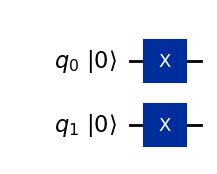

Wire order: q0 above q1; basis kets use |q1 q0⟩.

**State vector at the circuit output:**

<IPython.core.display.Latex object>

| Outcome | Exact probability | Expected count | Observed count |
|---|---:|---:|---:|
| 00 | 0.00 | 0 | 0 |
| 01 | 0.00 | 0 | 0 |
| 10 | 0.00 | 0 | 0 |
| 11 | 1.00 | 1024 | 1024 |

In [2]:
qc = QuantumCircuit(2)
qc.x(0)
qc.x(1)
counts_q1a = analyze(qc, np.kron(X, X), 'Question 1(a)')

### Qiskit Histograms Verifying the Measurement Predictions

Qiskit measurement snapshot for input |00⟩. The horizontal axis shows q1q0 outcomes; the vertical axis shows counts.

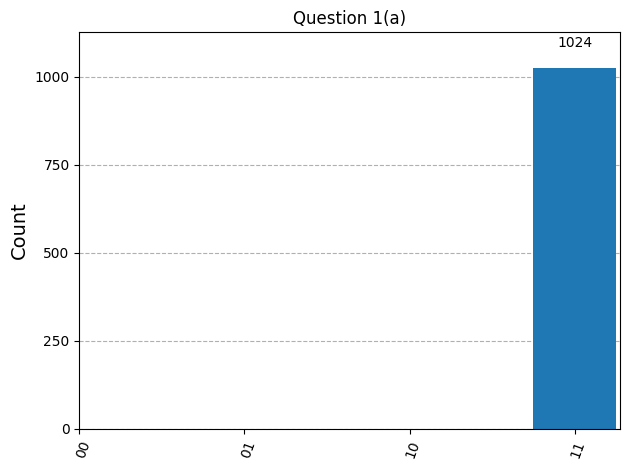

In [3]:
figure = plot_histogram(counts_q1a, title="Question 1(a)")

display(figure)
plt.close(figure)

Actual simulator counts: 00: 0; 01: 0; 10: 0; 11: 1024. All 1024 shots give 11, matching P(11) = 1 and probability 0 for the other outcomes.

## Question 1(b)

### 4×4 Operator Using the Kronecker Product Formulation

Only q0 receives X; q1 receives I. Thus U = I ⊗ X.

The entries of I are 1,0,0,1. They scale the four blocks in that order.

$$ I = \begin{bmatrix}1 & 0\\0 & 1\end{bmatrix}, \qquad X = \begin{bmatrix}0 & 1\\1 & 0\end{bmatrix}. $$

**Single-qubit actions:**

Multiply the two matrix rows by the input column. These are the only single-qubit actions needed for this part.

**Input $I|0\rangle$:**

$$ 1\cdot1 + 0\cdot0 = 1 $$

$$ 0\cdot1 + 1\cdot0 = 0 $$

Therefore $ I|0\rangle = |0\rangle $.

**Input $I|1\rangle$:**

$$ 1\cdot0 + 0\cdot1 = 0 $$

$$ 0\cdot0 + 1\cdot1 = 1 $$

Therefore $ I|1\rangle = |1\rangle $.

**Input $X|0\rangle$:**

$$ 0\cdot1 + 1\cdot0 = 0 $$

$$ 1\cdot1 + 0\cdot0 = 1 $$

Therefore $ X|0\rangle = |1\rangle $.

**Input $X|1\rangle$:**

$$ 0\cdot0 + 1\cdot1 = 1 $$

$$ 1\cdot0 + 0\cdot1 = 0 $$

Therefore $ X|1\rangle = |0\rangle $.

**Kronecker product expansion:**

Each entry of the left factor multiplies **every** entry of the right factor.

**Upper-left block:**

$$ (1)X = \begin{bmatrix}(1)\cdot(0) & (1)\cdot(1)\\(1)\cdot(1) & (1)\cdot(0)\end{bmatrix} $$

$$ = \begin{bmatrix}0 & 1\\1 & 0\end{bmatrix}. $$

**Upper-right block:**

$$ (0)X = \begin{bmatrix}(0)\cdot(0) & (0)\cdot(1)\\(0)\cdot(1) & (0)\cdot(0)\end{bmatrix} $$

$$ = \begin{bmatrix}0 & 0\\0 & 0\end{bmatrix}. $$

**Lower-left block:**

$$ (0)X = \begin{bmatrix}(0)\cdot(0) & (0)\cdot(1)\\(0)\cdot(1) & (0)\cdot(0)\end{bmatrix} $$

$$ = \begin{bmatrix}0 & 0\\0 & 0\end{bmatrix}. $$

**Lower-right block:**

$$ (1)X = \begin{bmatrix}(1)\cdot(0) & (1)\cdot(1)\\(1)\cdot(1) & (1)\cdot(0)\end{bmatrix} $$

$$ = \begin{bmatrix}0 & 1\\1 & 0\end{bmatrix}. $$

Place the upper two blocks side by side, then the lower two blocks:

$$ U = I \otimes X = \begin{bmatrix}0 & 1 & 0 & 0\\1 & 0 & 0 & 0\\0 & 0 & 0 & 1\\0 & 0 & 1 & 0\end{bmatrix}. $$

### Action of the Operator on the Kets: |00⟩, |01⟩, |10⟩, |11⟩

Use the single-qubit actions above. Multiply any scalar phases and distribute tensor products before combining the two bits.

**Input $|00\rangle$:**

$$ U|00\rangle = (I|0\rangle) \otimes (X|0\rangle) $$

$$  = |0\rangle \otimes |1\rangle $$

$$  = |01\rangle $$

**Input $|01\rangle$:**

$$ U|01\rangle = (I|0\rangle) \otimes (X|1\rangle) $$

$$  = |0\rangle \otimes |0\rangle $$

$$  = |00\rangle $$

**Input $|10\rangle$:**

$$ U|10\rangle = (I|1\rangle) \otimes (X|0\rangle) $$

$$  = |1\rangle \otimes |1\rangle $$

$$  = |11\rangle $$

**Input $|11\rangle$:**

$$ U|11\rangle = (I|1\rangle) \otimes (X|1\rangle) $$

$$  = |1\rangle \otimes |0\rangle $$

$$  = |10\rangle $$

### Probability Measurements

The initialized input is $|00\rangle=(1,0,0,0)^T$. Keep all four row products visible:

$$ U|00\rangle = \begin{bmatrix}0 & 1 & 0 & 0\\1 & 0 & 0 & 0\\0 & 0 & 0 & 1\\0 & 0 & 1 & 0\end{bmatrix}\begin{bmatrix}1\\0\\0\\0\end{bmatrix}. $$

**Row 1:** $ 0\cdot1 + 1\cdot0 + 0\cdot0 + 0\cdot0 = 0 $.

**Row 2:** $ 1\cdot1 + 0\cdot0 + 0\cdot0 + 0\cdot0 = 1 $.

**Row 3:** $ 0\cdot1 + 0\cdot0 + 0\cdot0 + 1\cdot0 = 0 $.

**Row 4:** $ 0\cdot1 + 0\cdot0 + 1\cdot0 + 0\cdot0 = 0 $.

$$ |\psi_f\rangle = \begin{bmatrix}0\\1\\0\\0\end{bmatrix} = |01\rangle. $$

**Probability measurements and normalization:**

Take the squared magnitude of each output amplitude, rather than the amplitude itself:

$P(00) = |0|^2 = 0\cdot0 = 0$.

$P(01) = |1|^2 = (1)(1) = 1$.

$P(10) = |0|^2 = 0\cdot0 = 0$.

$P(11) = |0|^2 = 0\cdot0 = 0$.

$$ 0 + 1 + 0 + 0 = 1. $$

For the other basis inputs above, there is exactly one nonzero coefficient, of magnitude 1. Its output ket has probability 1 and the other three outcomes have probability 0.

Verify the operator and all four basis actions, then compare the predicted probabilities with actual simulator counts.

Question 1(b): operator and all four basis actions verified against Qiskit.


### Circuit Diagram: Question 1(b)

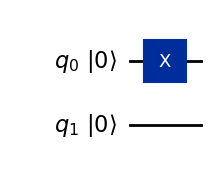

Wire order: q0 above q1; basis kets use |q1 q0⟩.

**State vector at the circuit output:**

<IPython.core.display.Latex object>

| Outcome | Exact probability | Expected count | Observed count |
|---|---:|---:|---:|
| 00 | 0.00 | 0 | 0 |
| 01 | 1.00 | 1024 | 1024 |
| 10 | 0.00 | 0 | 0 |
| 11 | 0.00 | 0 | 0 |

In [4]:
qc = QuantumCircuit(2)
qc.x(0)
counts_q1b = analyze(qc, np.kron(I2, X), 'Question 1(b)')

### Qiskit Histograms Verifying the Measurement Predictions

Qiskit measurement snapshot for input |00⟩. The horizontal axis shows q1q0 outcomes; the vertical axis shows counts.

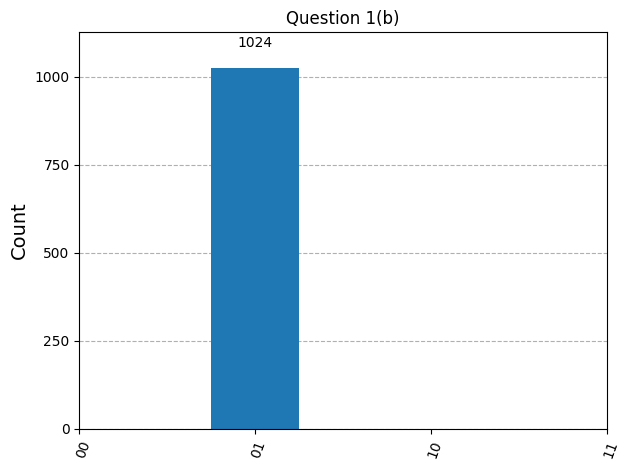

In [5]:
figure = plot_histogram(counts_q1b, title="Question 1(b)")

display(figure)
plt.close(figure)

Actual simulator counts: 00: 0; 01: 1024; 10: 0; 11: 0. All 1024 shots give 01, matching P(01) = 1 and probability 0 for the other outcomes.

## Question 1(c)

### 4×4 Operator Using the Kronecker Product Formulation

The first gate is H on q0: I ⊗ H. The second is H on q1: H ⊗ I. Thus U = (H ⊗ I)(I ⊗ H) = H ⊗ H.

Each H contains a factor 1/√2. Their product is (1/√2)(1/√2) = 1/(√2×√2) = 1/2. In the block table, the minus sign in the lower-right block multiplies every entry.

$$ H = \frac1{\sqrt2}\begin{bmatrix}1 & 1\\1 & -1\end{bmatrix}. $$

**Single-qubit actions:**

Multiply the two matrix rows by the input column. These are the only single-qubit actions needed for this part.

**Input $H|0\rangle$:**

$$ (1/\sqrt{2})[1\cdot1 + 1\cdot0] = 1/\sqrt{2} $$

$$ (1/\sqrt{2})[1\cdot1 + (-1)\cdot0] = 1/\sqrt{2} $$

Therefore $ H|0\rangle = (|0\rangle + |1\rangle)/\sqrt{2} $.

**Input $H|1\rangle$:**

$$ (1/\sqrt{2})[1\cdot0 + 1\cdot1] = 1/\sqrt{2} $$

$$ (1/\sqrt{2})[1\cdot0 + (-1)\cdot1] = -1/\sqrt{2} $$

Therefore $ H|1\rangle = (|0\rangle - |1\rangle)/\sqrt{2} $.

**Kronecker product expansion:**

Each entry of the left factor multiplies **every** entry of the right factor.

**Upper-left block:**

$$ (1/\sqrt{2})H = \begin{bmatrix}(1/\sqrt{2})\cdot(1/\sqrt{2}) & (1/\sqrt{2})\cdot(1/\sqrt{2})\\(1/\sqrt{2})\cdot(1/\sqrt{2}) & (1/\sqrt{2})\cdot(-1/\sqrt{2})\end{bmatrix} $$

$$ = \frac12\begin{bmatrix}1 & 1\\1 & -1\end{bmatrix}. $$

**Upper-right block:**

$$ (1/\sqrt{2})H = \begin{bmatrix}(1/\sqrt{2})\cdot(1/\sqrt{2}) & (1/\sqrt{2})\cdot(1/\sqrt{2})\\(1/\sqrt{2})\cdot(1/\sqrt{2}) & (1/\sqrt{2})\cdot(-1/\sqrt{2})\end{bmatrix} $$

$$ = \frac12\begin{bmatrix}1 & 1\\1 & -1\end{bmatrix}. $$

**Lower-left block:**

$$ (1/\sqrt{2})H = \begin{bmatrix}(1/\sqrt{2})\cdot(1/\sqrt{2}) & (1/\sqrt{2})\cdot(1/\sqrt{2})\\(1/\sqrt{2})\cdot(1/\sqrt{2}) & (1/\sqrt{2})\cdot(-1/\sqrt{2})\end{bmatrix} $$

$$ = \frac12\begin{bmatrix}1 & 1\\1 & -1\end{bmatrix}. $$

**Lower-right block:**

$$ (-1/\sqrt{2})H = \begin{bmatrix}(-1/\sqrt{2})\cdot(1/\sqrt{2}) & (-1/\sqrt{2})\cdot(1/\sqrt{2})\\(-1/\sqrt{2})\cdot(1/\sqrt{2}) & (-1/\sqrt{2})\cdot(-1/\sqrt{2})\end{bmatrix} $$

$$ = \frac12\begin{bmatrix}-1 & -1\\-1 & 1\end{bmatrix}. $$

Place the upper two blocks side by side, then the lower two blocks:

$$ U = H \otimes H = \frac12\begin{bmatrix}1 & 1 & 1 & 1\\1 & -1 & 1 & -1\\1 & 1 & -1 & -1\\1 & -1 & -1 & 1\end{bmatrix}. $$

### Action of the Operator on the Kets: |00⟩, |01⟩, |10⟩, |11⟩

Use the single-qubit actions above. Multiply any scalar phases and distribute tensor products before combining the two bits.

**Input $|00\rangle$:**

$$ U|00\rangle = (H|0\rangle) \otimes (H|0\rangle) $$

$$  = [(|0\rangle + |1\rangle)/\sqrt{2}] \otimes [(|0\rangle + |1\rangle)/\sqrt{2}] $$

$$  = (1/2)[(|0\rangle \otimes |0\rangle) + (|0\rangle \otimes |1\rangle) + (|1\rangle \otimes |0\rangle) + (|1\rangle \otimes |1\rangle)] $$

$$  = (1/2)(|00\rangle + |01\rangle + |10\rangle + |11\rangle) $$

**Input $|01\rangle$:**

$$ U|01\rangle = (H|0\rangle) \otimes (H|1\rangle) $$

$$  = [(|0\rangle + |1\rangle)/\sqrt{2}] \otimes [(|0\rangle - |1\rangle)/\sqrt{2}] $$

$$  = (1/2)[(|0\rangle \otimes |0\rangle) - (|0\rangle \otimes |1\rangle) + (|1\rangle \otimes |0\rangle) - (|1\rangle \otimes |1\rangle)] $$

$$  = (1/2)(|00\rangle - |01\rangle + |10\rangle - |11\rangle) $$

**Input $|10\rangle$:**

$$ U|10\rangle = (H|1\rangle) \otimes (H|0\rangle) $$

$$  = [(|0\rangle - |1\rangle)/\sqrt{2}] \otimes [(|0\rangle + |1\rangle)/\sqrt{2}] $$

$$  = (1/2)[(|0\rangle \otimes |0\rangle) + (|0\rangle \otimes |1\rangle) - (|1\rangle \otimes |0\rangle) - (|1\rangle \otimes |1\rangle)] $$

$$  = (1/2)(|00\rangle + |01\rangle - |10\rangle - |11\rangle) $$

**Input $|11\rangle$:**

$$ U|11\rangle = (H|1\rangle) \otimes (H|1\rangle) $$

$$  = [(|0\rangle - |1\rangle)/\sqrt{2}] \otimes [(|0\rangle - |1\rangle)/\sqrt{2}] $$

$$  = (1/2)[(|0\rangle \otimes |0\rangle) - (|0\rangle \otimes |1\rangle) - (|1\rangle \otimes |0\rangle) + (|1\rangle \otimes |1\rangle)] $$

$$  = (1/2)(|00\rangle - |01\rangle - |10\rangle + |11\rangle) $$

### Probability Measurements

The initialized input is $|00\rangle=(1,0,0,0)^T$. Keep all four row products visible:

$$ U|00\rangle = \frac12\begin{bmatrix}1 & 1 & 1 & 1\\1 & -1 & 1 & -1\\1 & 1 & -1 & -1\\1 & -1 & -1 & 1\end{bmatrix}\begin{bmatrix}1\\0\\0\\0\end{bmatrix}. $$

**Row 1:** $ (1/2)[1\cdot1 + 1\cdot0 + 1\cdot0 + 1\cdot0] = 1/2 $.

**Row 2:** $ (1/2)[1\cdot1 + (-1)\cdot0 + 1\cdot0 + (-1)\cdot0] = 1/2 $.

**Row 3:** $ (1/2)[1\cdot1 + 1\cdot0 + (-1)\cdot0 + (-1)\cdot0] = 1/2 $.

**Row 4:** $ (1/2)[1\cdot1 + (-1)\cdot0 + (-1)\cdot0 + 1\cdot0] = 1/2 $.

$$ |\psi_f\rangle = \frac12\begin{bmatrix}1\\1\\1\\1\end{bmatrix} = (1/2)(|00\rangle + |01\rangle + |10\rangle + |11\rangle). $$

**Probability measurements and normalization:**

Take the squared magnitude of each output amplitude, rather than the amplitude itself:

$P(00) = |1/2|^2 = (1/2)(1/2) = 1/4$.

$P(01) = |1/2|^2 = (1/2)(1/2) = 1/4$.

$P(10) = |1/2|^2 = (1/2)(1/2) = 1/4$.

$P(11) = |1/2|^2 = (1/2)(1/2) = 1/4$.

$$ 1/4 + 1/4 + 1/4 + 1/4 = 1. $$

For the other basis inputs above, each of the four coefficients is +1/2 or −1/2. Squaring either sign gives (±1/2)² = 1/4, so every input has the same four basis probabilities.

Verify the operator and all four basis actions, then compare the predicted probabilities with actual simulator counts.

Question 1(c): operator and all four basis actions verified against Qiskit.


### Circuit Diagram: Question 1(c)

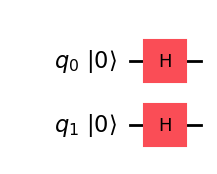

Wire order: q0 above q1; basis kets use |q1 q0⟩.

**State vector at the circuit output:**

<IPython.core.display.Latex object>

| Outcome | Exact probability | Expected count | Observed count |
|---|---:|---:|---:|
| 00 | 0.25 | 256 | 264 |
| 01 | 0.25 | 256 | 275 |
| 10 | 0.25 | 256 | 252 |
| 11 | 0.25 | 256 | 233 |

In [6]:
qc = QuantumCircuit(2)
qc.h(0)
qc.h(1)
counts_q1c = analyze(qc, np.kron(H, H), 'Question 1(c)')

### Qiskit Histograms Verifying the Measurement Predictions

Qiskit measurement snapshot for input |00⟩. The horizontal axis shows q1q0 outcomes; the vertical axis shows counts.

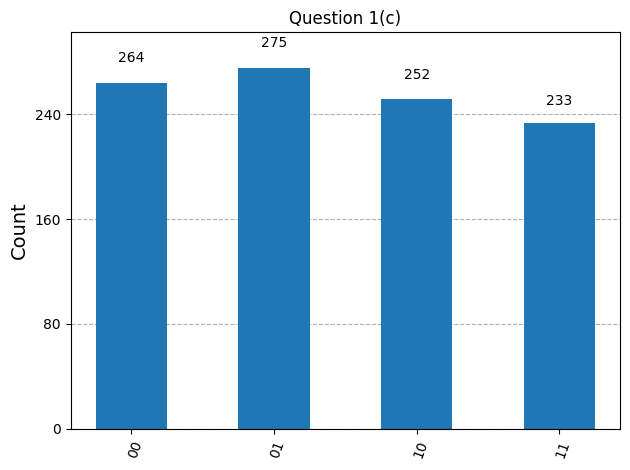

In [7]:
figure = plot_histogram(counts_q1c, title="Question 1(c)")

display(figure)
plt.close(figure)

Actual simulator counts: 00: 264; 01: 275; 10: 252; 11: 233. The prediction is probability 1/4 for every outcome, or 256 counts per outcome on average. The observed bars are approximately equal; their small differences arise from finite-shot sampling in the ideal simulator. For one outcome, the count standard deviation is $\sigma=\sqrt{Np(1-p)}=\sqrt{1024(1/4)(3/4)}\approx13.9$ counts. This gives the typical scale of variation across repeated runs; differences larger than one standard deviation can occur.

## Question 1(d)

### 4×4 Operator Using the Kronecker Product Formulation

The first gate is Z on q0: I ⊗ Z. The second is Y on q1: Y ⊗ I. Thus U = (Y ⊗ I)(I ⊗ Z) = (YI) ⊗ (IZ) = Y ⊗ Z.

The entries of Y are 0,−i,i,0. They scale the four blocks in that order. In particular, (−i)(−1) = i and i(−1) = −i; retain these signs.

$$ Y = \begin{bmatrix}0 & -i\\i & 0\end{bmatrix}, \qquad Z = \begin{bmatrix}1 & 0\\0 & -1\end{bmatrix}. $$

**Single-qubit actions:**

Multiply the two matrix rows by the input column. These are the only single-qubit actions needed for this part.

**Input $Y|0\rangle$:**

$$ 0\cdot1 + (-i)\cdot0 = 0 $$

$$ i\cdot1 + 0\cdot0 = i $$

Therefore $ Y|0\rangle = i|1\rangle $.

**Input $Y|1\rangle$:**

$$ 0\cdot0 + (-i)\cdot1 = -i $$

$$ i\cdot0 + 0\cdot1 = 0 $$

Therefore $ Y|1\rangle = -i|0\rangle $.

**Input $Z|0\rangle$:**

$$ 1\cdot1 + 0\cdot0 = 1 $$

$$ 0\cdot1 + (-1)\cdot0 = 0 $$

Therefore $ Z|0\rangle = |0\rangle $.

**Input $Z|1\rangle$:**

$$ 1\cdot0 + 0\cdot1 = 0 $$

$$ 0\cdot0 + (-1)\cdot1 = -1 $$

Therefore $ Z|1\rangle = -1|1\rangle $.

**Kronecker product expansion:**

Each entry of the left factor multiplies **every** entry of the right factor.

**Upper-left block:**

$$ (0)Z = \begin{bmatrix}(0)\cdot(1) & (0)\cdot(0)\\(0)\cdot(0) & (0)\cdot(-1)\end{bmatrix} $$

$$ = \begin{bmatrix}0 & 0\\0 & 0\end{bmatrix}. $$

**Upper-right block:**

$$ (-i)Z = \begin{bmatrix}(-i)\cdot(1) & (-i)\cdot(0)\\(-i)\cdot(0) & (-i)\cdot(-1)\end{bmatrix} $$

$$ = \begin{bmatrix}-i & 0\\0 & i\end{bmatrix}. $$

**Lower-left block:**

$$ (i)Z = \begin{bmatrix}(i)\cdot(1) & (i)\cdot(0)\\(i)\cdot(0) & (i)\cdot(-1)\end{bmatrix} $$

$$ = \begin{bmatrix}i & 0\\0 & -i\end{bmatrix}. $$

**Lower-right block:**

$$ (0)Z = \begin{bmatrix}(0)\cdot(1) & (0)\cdot(0)\\(0)\cdot(0) & (0)\cdot(-1)\end{bmatrix} $$

$$ = \begin{bmatrix}0 & 0\\0 & 0\end{bmatrix}. $$

Place the upper two blocks side by side, then the lower two blocks:

$$ U = Y \otimes Z = \begin{bmatrix}0 & 0 & -i & 0\\0 & 0 & 0 & i\\i & 0 & 0 & 0\\0 & -i & 0 & 0\end{bmatrix}. $$

### Action of the Operator on the Kets: |00⟩, |01⟩, |10⟩, |11⟩

Use the single-qubit actions above. Multiply any scalar phases and distribute tensor products before combining the two bits.

**Input $|00\rangle$:**

$$ U|00\rangle = (Y|0\rangle) \otimes (Z|0\rangle) $$

$$  = (i|1\rangle) \otimes (1|0\rangle) $$

$$  = (i)(1)|10\rangle $$

$$  = i|10\rangle $$

**Input $|01\rangle$:**

$$ U|01\rangle = (Y|0\rangle) \otimes (Z|1\rangle) $$

$$  = (i|1\rangle) \otimes (-1|1\rangle) $$

$$  = (i)(-1)|11\rangle $$

$$  = -i|11\rangle $$

**Input $|10\rangle$:**

$$ U|10\rangle = (Y|1\rangle) \otimes (Z|0\rangle) $$

$$  = (-i|0\rangle) \otimes (1|0\rangle) $$

$$  = (-i)(1)|00\rangle $$

$$  = -i|00\rangle $$

**Input $|11\rangle$:**

$$ U|11\rangle = (Y|1\rangle) \otimes (Z|1\rangle) $$

$$  = (-i|0\rangle) \otimes (-1|1\rangle) $$

$$  = (-i)(-1)|01\rangle $$

$$  = i|01\rangle $$

### Probability Measurements

The initialized input is $|00\rangle=(1,0,0,0)^T$. Keep all four row products visible:

$$ U|00\rangle = \begin{bmatrix}0 & 0 & -i & 0\\0 & 0 & 0 & i\\i & 0 & 0 & 0\\0 & -i & 0 & 0\end{bmatrix}\begin{bmatrix}1\\0\\0\\0\end{bmatrix}. $$

**Row 1:** $ 0\cdot1 + 0\cdot0 + (-i)\cdot0 + 0\cdot0 = 0 $.

**Row 2:** $ 0\cdot1 + 0\cdot0 + 0\cdot0 + i\cdot0 = 0 $.

**Row 3:** $ i\cdot1 + 0\cdot0 + 0\cdot0 + 0\cdot0 = i $.

**Row 4:** $ 0\cdot1 + (-i)\cdot0 + 0\cdot0 + 0\cdot0 = 0 $.

$$ |\psi_f\rangle = \begin{bmatrix}0\\0\\i\\0\end{bmatrix} = i|10\rangle. $$

**Probability measurements and normalization:**

Take the squared magnitude of each output amplitude, rather than the amplitude itself:

$P(00) = |0|^2 = 0\cdot0 = 0$.

$P(01) = |0|^2 = 0\cdot0 = 0$.

$P(10) = |i|^2 = (-i)i = -i^2 = -(-1) = 1$.

$P(11) = |0|^2 = 0\cdot0 = 0$.

$$ 0 + 0 + 1 + 0 = 1. $$

For the other basis inputs above, there is exactly one nonzero coefficient, of magnitude 1. Its output ket has probability 1 and the other three outcomes have probability 0.

Verify the operator and all four basis actions, then compare the predicted probabilities with actual simulator counts.

Question 1(d): operator and all four basis actions verified against Qiskit.


### Circuit Diagram: Question 1(d)

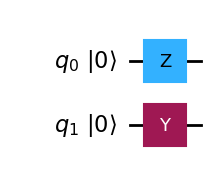

Wire order: q0 above q1; basis kets use |q1 q0⟩.

**State vector at the circuit output:**

<IPython.core.display.Latex object>

| Outcome | Exact probability | Expected count | Observed count |
|---|---:|---:|---:|
| 00 | 0.00 | 0 | 0 |
| 01 | 0.00 | 0 | 0 |
| 10 | 1.00 | 1024 | 1024 |
| 11 | 0.00 | 0 | 0 |

In [8]:
qc = QuantumCircuit(2)
qc.z(0)
qc.y(1)
counts_q1d = analyze(qc, np.kron(Y, Z), 'Question 1(d)')

### Qiskit Histograms Verifying the Measurement Predictions

Qiskit measurement snapshot for input |00⟩. The horizontal axis shows q1q0 outcomes; the vertical axis shows counts.

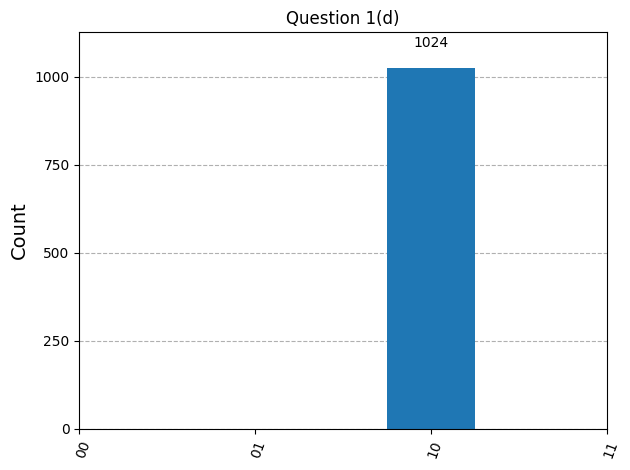

In [9]:
figure = plot_histogram(counts_q1d, title="Question 1(d)")

display(figure)
plt.close(figure)

Actual simulator counts: 00: 0; 01: 0; 10: 1024; 11: 0. All 1024 shots give 10, matching P(10) = 1 and probability 0 for the other outcomes. The global phase i in i|10⟩ does not change measurement probabilities.

## Question 2: Output State Vector

The input is |00⟩. The diagram applies H to q0, followed by a controlled-X with q0 as control and q1 as target. The connected control and X therefore mean `qc.cx(0, 1)`. Barriers do not change the state.

The operator is I ⊗ H because q1 is unchanged:

$$ (I\otimes H)|00\rangle=|0\rangle\otimes\frac{|0\rangle+|1\rangle}{\sqrt2}=\frac{|00\rangle+|01\rangle}{\sqrt2}. $$

In the ordered basis 00,01,10,11, this is

$$ |\psi_1\rangle=\frac1{\sqrt2}\begin{bmatrix}1\\1\\0\\0\end{bmatrix}. $$

CNOT leaves a branch unchanged when its rightmost bit q0 is 0 and flips q1 when q0 is 1. Thus C|00⟩ = |00⟩ and C|01⟩ = |11⟩. Its matrix is

$$ C=\begin{bmatrix}1&0&0&0\\0&0&0&1\\0&0&1&0\\0&1&0&0\end{bmatrix}. $$

Apply it to the state after H:

$$ C|\psi_1\rangle=\frac{C|00\rangle+C|01\rangle}{\sqrt2}=\frac{|00\rangle+|11\rangle}{\sqrt2}. $$

**Output state vector:**

$$ \boxed{|\psi_{out}\rangle=\frac1{\sqrt2}\begin{bmatrix}1\\0\\0\\1\end{bmatrix}=\frac{|00\rangle+|11\rangle}{\sqrt2}}. $$

This normalized Bell state is the coherent output immediately before the measurement gates: (1/√2)² + (1/√2)² = 1. The final measurements give the conditional state |00⟩ or |11⟩, each with probability 1/2. There is no single pure output vector for an unrecorded measurement outcome.

The Bell state above is entangled: it cannot be written as two independent single-qubit states. To see why, expand a possible product:

$$ (a|0\rangle+b|1\rangle)\otimes(c|0\rangle+d|1\rangle) $$

$$ =ac|00\rangle+ad|01\rangle+bc|10\rangle+bd|11\rangle. $$

Matching the Bell state would require both ac and bd to equal 1/√2, so a, b, c, and d must all be nonzero. Then ad and bc would also be nonzero, contradicting the zero coefficients of |01⟩ and |10⟩. Therefore the output cannot be factored into separate qubit states.

The two qubits give matching measurement outcomes, 00 or 11, each with probability 1/2. A classical mixture of these two outcomes gives the same computational-basis probabilities. The ideal statevector calculation establishes the coherent Bell state produced before measurement.

Verify the state before measurement and display the circuit with the measurement gates shown in the assignment.

<IPython.core.display.Latex object>

### Circuit Diagram: Question 2

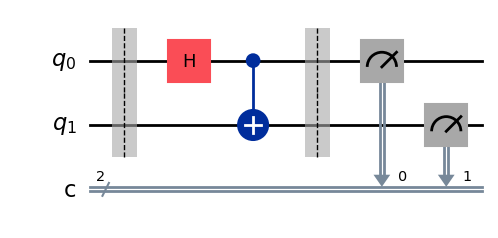

In [10]:
qc2 = QuantumCircuit(2, 2)
qc2.barrier()
qc2.h(0)
qc2.cx(0, 1)
qc2.barrier()
psi_out = Statevector.from_label("00").evolve(qc2)
assert np.allclose(psi_out.data, np.array([1, 0, 0, 1]) / np.sqrt(2))
display(array_to_latex(psi_out.data.reshape(-1, 1), prefix=r"|\psi_{out}\rangle = "))
qc2.measure([0, 1], [0, 1])
display(Markdown("### Circuit Diagram: Question 2"))
figure = qc2.draw("mpl")
display(figure)
plt.close(figure)

## Observations for Questions 1 and 2

For the default input |00⟩, the predicted probabilities and recorded simulator counts are summarized below. Every count tuple uses the outcome order (00, 01, 10, 11), and each circuit was sampled with 1024 shots.

| Circuit | Predicted probabilities | Observed counts |
|---|---|---|
| Question 1(a) | (0, 0, 0, 1) | (0, 0, 0, 1024) |
| Question 1(b) | (0, 1, 0, 0) | (0, 1024, 0, 0) |
| Question 1(c) | (1/4, 1/4, 1/4, 1/4) | (264, 275, 252, 233) |
| Question 1(d) | (0, 0, 1, 0) | (0, 0, 1024, 0) |

The deterministic circuits agree exactly with their predictions: applying X to both qubits produces |11⟩, applying X only to q0 produces |01⟩, and the Y-and-Z circuit produces i|10⟩. The global phase i in this last output does not change its measurement probabilities. The four possible input kets and their phases are checked separately in the worked answers and verification code.

For Question 1(c), the Hadamard gates give probability 1/4 to each outcome. The observed counts are close to the expected 256 per outcome. Their unequal heights reflect finite-shot sampling; the previously calculated count standard deviation is about 13.9. These measurements come from an ideal simulator and do not measure physical device noise.

For Question 2, the verified output vector has equal nonzero amplitudes only for |00⟩ and |11⟩, giving the Bell state (|00⟩ + |11⟩)/√2 before measurement. The state is entangled, and the predicted measurement outcomes are 00 and 11, each with probability 1/2. The statevector calculation also retains the coherence that a measurement histogram alone cannot establish.

## Question 3: Representation of Qubits on an IBM Quantum Computer

IBM implements physical qubits using superconducting *transmon* circuits, which contain a Josephson junction connected in parallel with a capacitor (IBM, n.d.). The junction makes the circuit an anharmonic oscillator: successive energy levels have different spacings, allowing a microwave drive to address the qubit transition selectively (Koch et al., 2007). A large shunt capacitance reduces sensitivity to charge noise (Koch et al., 2007). The ground and first excited energy states represent |0⟩ and |1⟩. Within this two-state computational subspace, a pure qubit state is |ψ⟩ = α|0⟩ + β|1⟩, where the complex amplitudes satisfy |α|² + |β|² = 1; their magnitudes and relative phase specify the state (Krantz et al., 2019). A transmon physically has higher energy levels, so pulse shaping suppresses unintended excitation outside |0⟩ and |1⟩ (Krantz et al., 2019).

The processor operates inside a dilution refrigerator at millikelvin temperatures to support superconductivity and reduce thermal excitation (Krantz et al., 2019). Calibrated microwave pulses control the qubit state and implement gates (IBM, n.d.). Measurement uses a coupled microwave resonator whose response depends on the qubit state; the amplified signal is classified as a classical 0 or 1 (Krantz et al., 2019). Ideally, measuring α|0⟩ + β|1⟩ produces 0 with probability |α|² and 1 with probability |β|². Repeated preparations estimate these probabilities; a single measurement does not reveal both complex amplitudes (Krantz et al., 2019). Energy relaxation, loss of relative phase (dephasing), and readout errors limit physical devices (Krantz et al., 2019).

## Conclusion

The Kronecker-product calculations and Qiskit verification agree for all four Question 1 operators and all four computational-basis inputs. Their output probabilities are normalized, and the histogram snapshots support the predictions for the initialized input |00⟩. The Bell-state circuit shows how a Hadamard gate followed by a controlled-X gate creates entanglement. Together with the discussion of IBM's superconducting qubits, these results connect the mathematical description of quantum computation to simulation and physical implementation, while keeping ideal predictions distinct from the limitations of real devices.

### References

IBM. (n.d.). *Running quantum circuits*. IBM Quantum Learning. [https://quantum.cloud.ibm.com/learning/en/courses/quantum-computing-in-practice/running-quantum-circuits](https://quantum.cloud.ibm.com/learning/en/courses/quantum-computing-in-practice/running-quantum-circuits)

Koch, J., Yu, T. M., Gambetta, J., Houck, A. A., Schuster, D. I., Majer, J., Blais, A., Devoret, M. H., Girvin, S. M., & Schoelkopf, R. J. (2007). Charge-insensitive qubit design derived from the Cooper pair box. *Physical Review A, 76*(4), Article 042319. [https://doi.org/10.1103/PhysRevA.76.042319](https://doi.org/10.1103/PhysRevA.76.042319)

Krantz, P., Kjaergaard, M., Yan, F., Orlando, T. P., Gustavsson, S., & Oliver, W. D. (2019). A quantum engineer's guide to superconducting qubits. *Applied Physics Reviews, 6*(2), Article 021318. [https://doi.org/10.1063/1.5089550](https://doi.org/10.1063/1.5089550)